In [24]:
#Bolli Yaswanth Melki , 92400133114 , 5EK2B , Kernel based image processing

RGB shape: (432, 768, 3) | Gray shape: (432, 768)


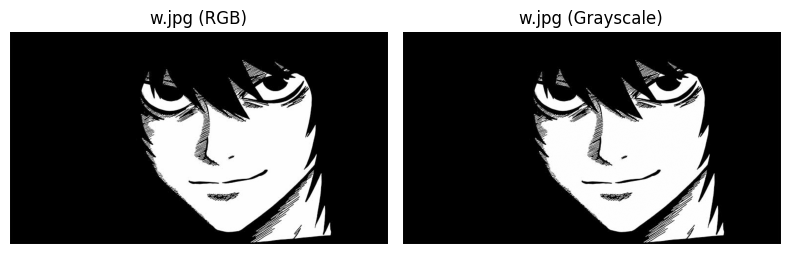

In [25]:
import cv2
import matplotlib.pyplot as plt

img_path = "/content/w.jpg"
bgr = cv2.imread(img_path)

if bgr is None:
    raise FileNotFoundError(f"Could not read image at {img_path}")

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

print("RGB shape:", rgb.shape, "| Gray shape:", gray.shape)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("w.jpg (RGB)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("w.jpg (Grayscale)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
kernels = {
    "Identity": np.array([
        [0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.float32),

    "Box Blur (5x5)": np.ones((5, 5), dtype=np.float32) / 25.0,

    "Gaussian Blur (3x3)": np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16.0,

    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    "Laplacian (Edge)": np.array([
        [0,  1, 0],
        [1, -4, 1],
        [0,  1, 0]
    ], dtype=np.float32),

    "Sobel X (Vertical Edges)": np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float32),

    "Sobel Y (Horizontal Edges)": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Emboss": np.array([
        [-2, -1, 0],
        [-1,  1, 1],
        [ 0,  1, 2]
    ], dtype=np.float32),
}

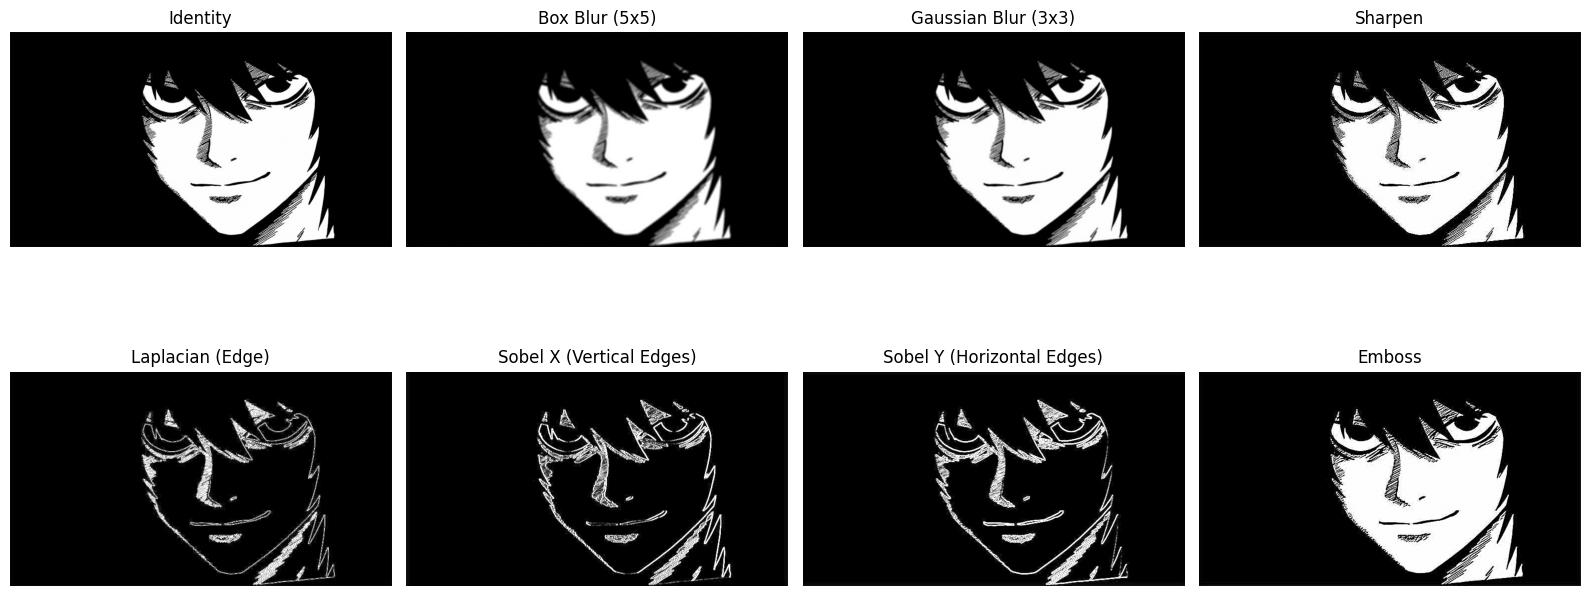

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, k) in zip(axes.flat, kernels.items()):
    filtered = cv2.filter2D(gray, ddepth=cv2.CV_32F, kernel=k)
    if "Sobel" in name or "Laplacian" in name:
        display_img = np.clip(np.abs(filtered), 0, 255).astype(np.uint8)
    else:
        display_img = np.clip(filtered, 0, 255).astype(np.uint8)
    ax.imshow(display_img, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

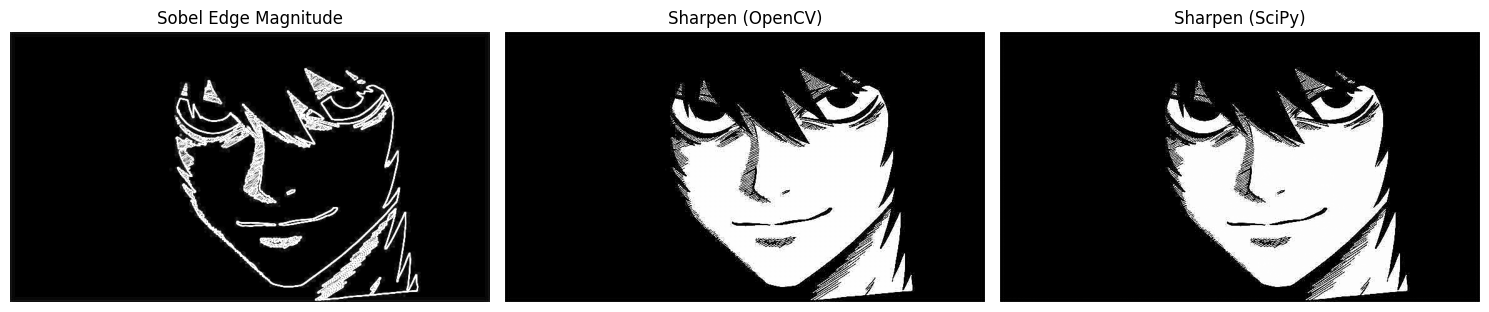

In [29]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import convolve

# Combine Sobel X and Sobel Y into Edge Magnitude
gx = cv2.filter2D(gray.astype(np.float32), -1, kernels["Sobel X (Vertical Edges)"])
gy = cv2.filter2D(gray.astype(np.float32), -1, kernels["Sobel Y (Horizontal Edges)"])
sobel_mag = np.clip(np.sqrt(gx**2 + gy**2), 0, 255).astype(np.uint8)

# Pure NumPy 2D convolution helper for understanding how kernels slide over pixels
def conv2d_numpy(image, kernel):
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image.astype(np.float32), ((pad_h, pad_h), (pad_w, pad_w)), mode="edge")
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + kh, j:j + kw]
            output[i, j] = np.sum(region * kernel)
    return output

# Verify SciPy convolve vs OpenCV filter2D on Sharpen
# Note: scipy.signal.convolve flips the kernel (true convolution), whereas cv2.filter2D performs correlation
sharpen_cv = np.clip(
    cv2.filter2D(gray.astype(np.float32), -1, kernels["Sharpen"]), 0, 255
).astype(np.uint8)
sharpen_sp = np.clip(
    convolve(gray.astype(np.float32), kernels["Sharpen"], mode="same"), 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sobel_mag, cmap="gray")
axes[0].set_title("Sobel Edge Magnitude")
axes[0].axis("off")

axes[1].imshow(sharpen_cv, cmap="gray")
axes[1].set_title("Sharpen (OpenCV)")
axes[1].axis("off")

axes[2].imshow(sharpen_sp, cmap="gray")
axes[2].set_title("Sharpen (SciPy)")
axes[2].axis("off")

plt.tight_layout()
plt.show()